# Project 2 – Milestone 2: Baseline Conditional Generation

This notebook uses pretrained Stable Diffusion v1.5 with its built-in CLIP text encoder to generate images from our 16 COCO 2017 captions.

We use the same prompts and random seeds from Milestone 1 to establish a reproducible baseline for the guidance-scale and sampling experiments.

Each image is generated using 25 inference steps and the default guidance scale of 7.5.

In [4]:
!pip install -q diffusers transformers accelerate safetensors
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [5]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [7]:
import os

os.makedirs("milestone2_baseline", exist_ok=True)

In [9]:
import pandas as pd

prompts = pd.read_csv("baseline_prompts.csv")

for _, row in prompts.iterrows():
    generator = torch.Generator(device="cuda").manual_seed(int(row["seed"]))

    image = pipe(
        row["prompt"],
        generator=generator,
        num_inference_steps=25,
        guidance_scale=7.5
    ).images[0]

    image.save(f"milestone2_baseline/{row['prompt_id']}.png")

    print(f"Finished {row['prompt_id']}")

  0%|          | 0/25 [00:00<?, ?it/s]

Finished p01


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p02


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p03


... (22 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

Finished p15


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p16


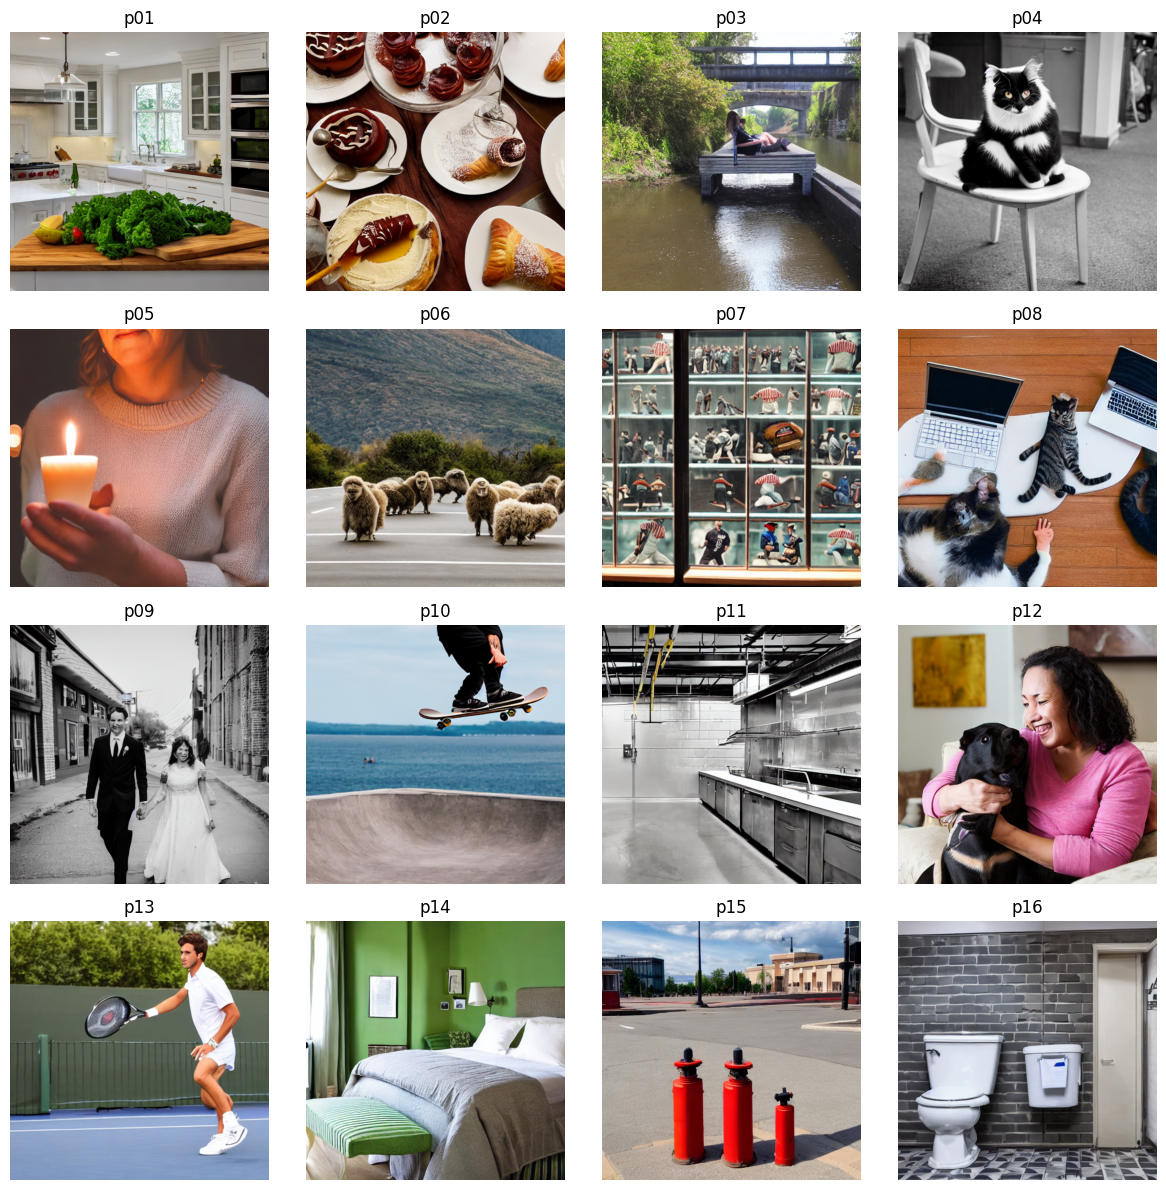

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for ax, (_, row) in zip(axes.flat, prompts.iterrows()):
    prompt_id = row["prompt_id"]
    image = Image.open(f"milestone2_baseline/{prompt_id}.png")

    ax.imshow(image)
    ax.set_title(prompt_id)
    ax.axis("off")

plt.tight_layout()
plt.savefig("milestone2_baseline_gallery.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
from google.colab import files

files.download("milestone2_baseline_gallery.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>